In [2]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Rows and columns: (1000, 9)

First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows:
0


In [4]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number").columns

# Calculate mean, median, mode, and standard deviation
stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})

print("Descriptive Statistics:")
display(stats.round(2))

Descriptive Statistics:


,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


In [5]:
# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check the date range
print("Earliest transaction date:", df["Date"].min())
print("Latest transaction date:", df["Date"].max())

# Create month and quarter columns
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

print("\nDate conversion completed!")
display(df[["Date", "Month", "Quarter", "Total Amount"]].head())

Earliest transaction date: 2023-01-01 00:00:00
Latest transaction date: 2024-01-01 00:00:00

Date conversion completed!


,Date,Month,Quarter,Total Amount
0,2023-11-24,2023-11,2023Q4,150
1,2023-02-27,2023-02,2023Q1,1000
2,2023-01-13,2023-01,2023Q1,30
3,2023-05-21,2023-05,2023Q2,500
4,2023-05-06,2023-05,2023Q2,100


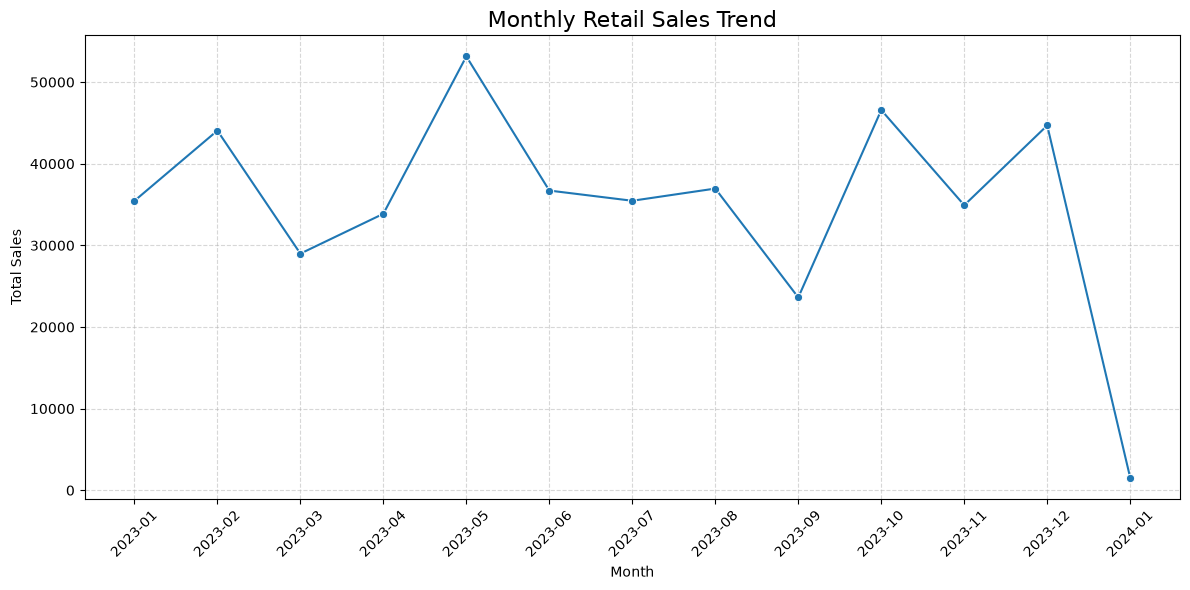

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total sales for each month
monthly_sales = df.groupby("Month")["Total Amount"].sum()

# Create the line chart
plt.figure(figsize=(12, 6))
sns.lineplot(
    x=monthly_sales.index.astype(str),
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Retail Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Observation
Monthly sales fluctuated throughout the observed period. Sales reached their highest level in May 2023, while January 2024 recorded the lowest total. Since January 2024 contains very low sales compared with previous months, this result should be checked before making business decisions.

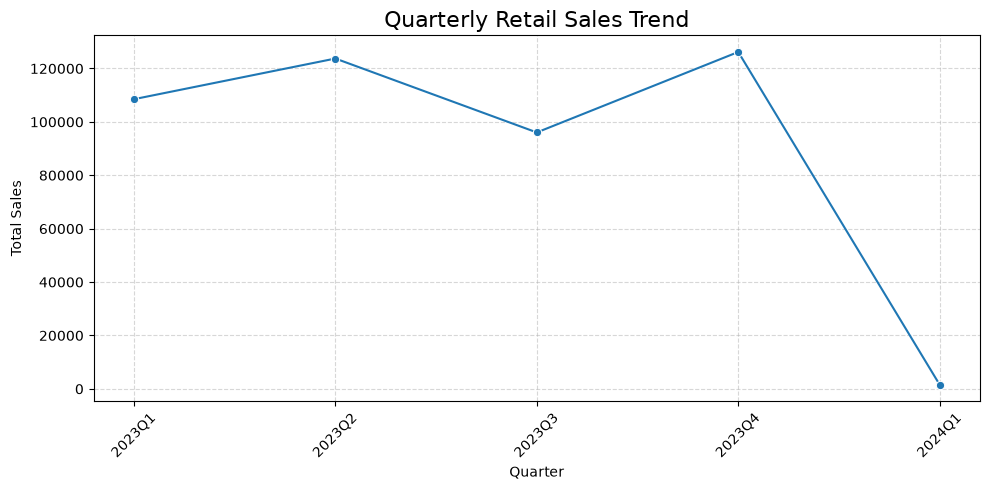

Quarterly Sales:


Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

In [10]:
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(10, 5))
sns.lineplot(
    x=quarterly_sales.index.astype(str),
    y=quarterly_sales.values,
    marker="o"
)

plt.title("Quarterly Retail Sales Trend", fontsize=16)
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Quarterly Sales:")
display(quarterly_sales)

### Observation
Quarterly sales were highest in Q4 2023, reaching 126,190, and lowest in Q1 2024, at 1,530. Sales increased from Q1 to Q2 2023, declined in Q3, and recovered in Q4. The sharp drop in Q1 2024 should be investigated because the dataset contains only January 2024 transactions in that quarter.

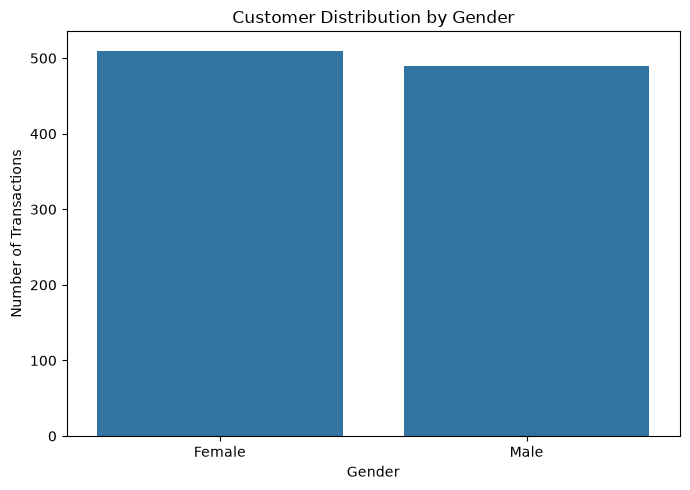

Gender counts:


Gender
Female    510
Male      490
Name: count, dtype: int64

In [12]:
# Count customers by gender
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=gender_counts.index, y=gender_counts.values)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

print("Gender counts:")
display(gender_counts)

### Observation
Female customers accounted for 510 transactions, while male customers accounted for 490 transactions. The distribution is nearly balanced, with female customers making up a slightly larger share of recorded transactions. The business can examine spending patterns by gender to understand whether purchasing behaviour differs between the groups.

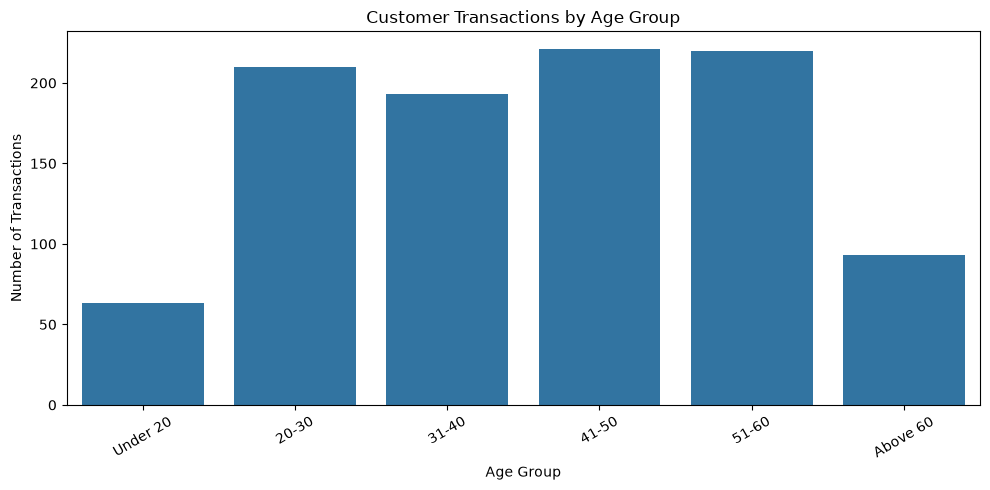

Transactions by age group:


Age Group
Under 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64

In [13]:
# Create customer age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["Under 20", "20-30", "31-40", "41-50", "51-60", "Above 60"],
    include_lowest=True
)

# Count transactions in each age group
age_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=age_counts.index.astype(str), y=age_counts.values)

plt.title("Customer Transactions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Transactions by age group:")
display(age_counts)

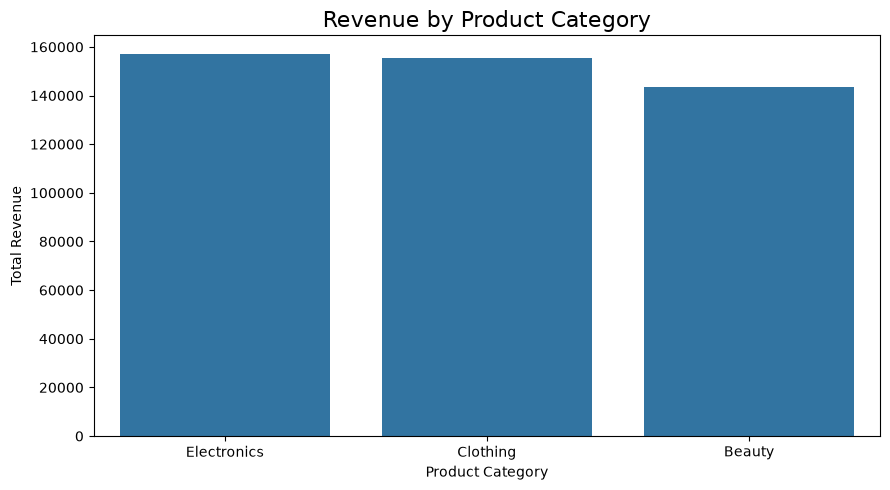

Revenue by Product Category:


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [14]:
# Calculate total revenue for each product category
category_sales = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

# Create the revenue chart
plt.figure(figsize=(9, 5))
sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Revenue by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

print("Revenue by Product Category:")
display(category_sales)

### Observation
The chart compares total revenue across Beauty, Clothing, and Electronics. The category with the highest revenue contributes the most to overall sales, while the lowest-revenue category may need further analysis of pricing, demand, and promotional strategies.

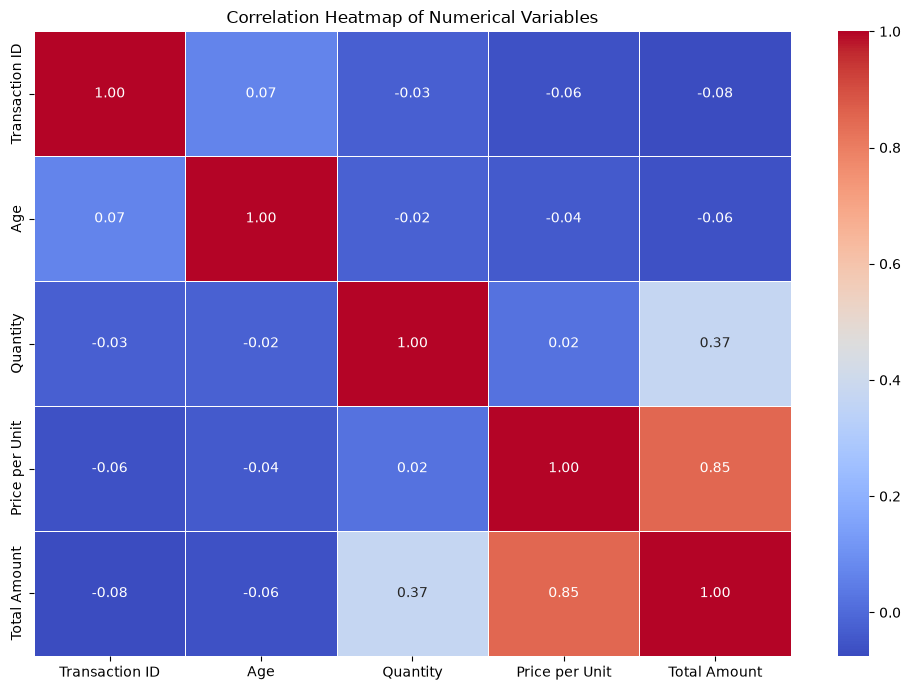

In [15]:
# Select numerical columns for correlation analysis
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### Observation
The correlation heatmap shows the strength and direction of relationships between numerical variables. Values closer to +1 indicate a strong positive relationship, values closer to -1 indicate a strong negative relationship, and values near 0 indicate a weak linear relationship. The specific relationships should be interpreted from the displayed values.

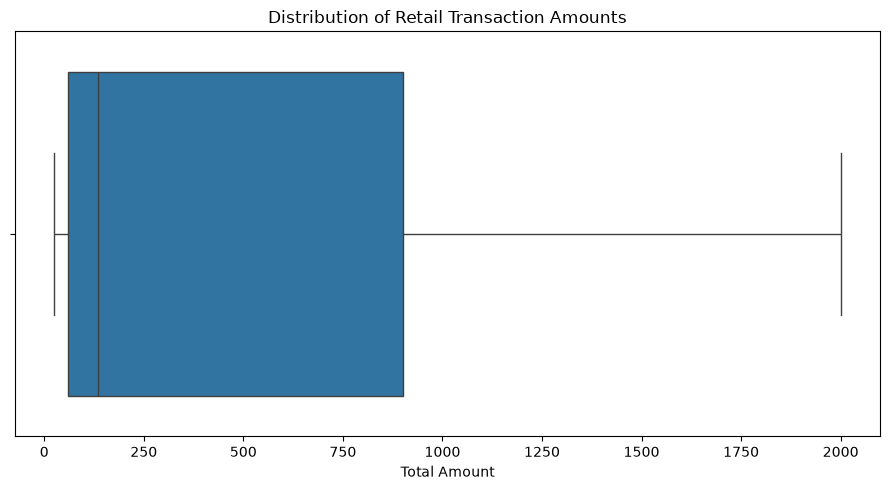

Transaction Amount Summary:


count    1000.000000
mean      456.000000
std       559.997632
min        25.000000
25%        60.000000
50%       135.000000
75%       900.000000
max      2000.000000
Name: Total Amount, dtype: float64

In [16]:
# Visualize the distribution of transaction amounts
plt.figure(figsize=(9, 5))

sns.boxplot(x=df["Total Amount"])

plt.title("Distribution of Retail Transaction Amounts")
plt.xlabel("Total Amount")
plt.tight_layout()
plt.show()

print("Transaction Amount Summary:")
display(df["Total Amount"].describe())

### Observation
The boxplot summarizes the distribution of transaction amounts. The median shows the middle transaction value, while the box and whiskers show the spread of the data. Points beyond the whiskers may indicate unusually high or low transactions that could be examined further.

In [17]:
# Save the prepared dataset
df.to_csv("retail_sales_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", df.shape)

Cleaned dataset saved successfully!
Rows and columns: (1000, 12)


## Conclusion

The exploratory data analysis of the retail sales dataset helped identify sales trends, customer characteristics, and product category performance. The dataset contains 1,000 transactions and nine original columns. During inspection, no missing values or duplicate rows were found.

Monthly and quarterly sales charts showed changes in sales over time. Customer analysis revealed a nearly balanced distribution of female and male transactions. Descriptive statistics and the transaction amount boxplot provided further information about purchasing patterns and the spread of transaction values.

The analysis also highlighted an unusually low sales total in January 2024 compared with earlier periods. This should be investigated before making decisions based on the trend.

## Business Recommendations

1. **Investigate sales fluctuations:** Review the unusually low January 2024 sales and compare them with transaction records and business activity before deciding whether corrective action is needed.

2. **Improve category-level planning:** Use the revenue comparison across Beauty, Clothing, and Electronics to guide inventory planning and promotional campaigns, giving attention to each category's actual performance.

3. **Understand customer purchasing patterns:** Analyze spending and product preferences across age groups and genders to design relevant marketing campaigns and improve the customer experience.

## Final Outcome

The project demonstrates how Python, Pandas, Matplotlib, and Seaborn can be used to inspect retail data, calculate descriptive statistics, visualize sales trends, and generate insights that support business decisions.